%%markdown
# Building segmentation: pixels and objects

Two neighboring buildings are represented by simple **synthetic masks**.
This is a controlled illustration, not aerial imagery, real footprints, or
a model result. Compare an exact prediction, a merged prediction, and a
background-only prediction. Why can a map with almost perfect pixel overlap
still produce the wrong building count?

[Open in Colab](https://colab.research.google.com/github/jfemiani/cse620b-public/blob/main/Lessons/12-Urban-Infrastructure/demo-building-metrics.ipynb) |
[Urban infrastructure lecture](https://github.com/jfemiani/cse620b-public/blob/main/Lessons/12-Urban-Infrastructure/slides/urban-infrastructure.md) |
[Real imagery companion](https://github.com/jfemiani/cse620b-public/blob/main/Lessons/12-Urban-Infrastructure/demo-building-imagery.ipynb)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix

reference = np.zeros((80, 80), dtype=bool)
reference[25:45, 15:35] = True
reference[25:45, 37:57] = True
perfect = reference.copy()
merged = reference.copy()
merged[34:36, 35:37] = True
background = np.zeros_like(reference)
predictions = {"Exact": perfect, "Merged": merged, "Background only": background}

%%markdown
## Inspect the masks

The merged prediction adds only four pixels, joining two buildings into one
connected region. The background-only map predicts no building pixels.

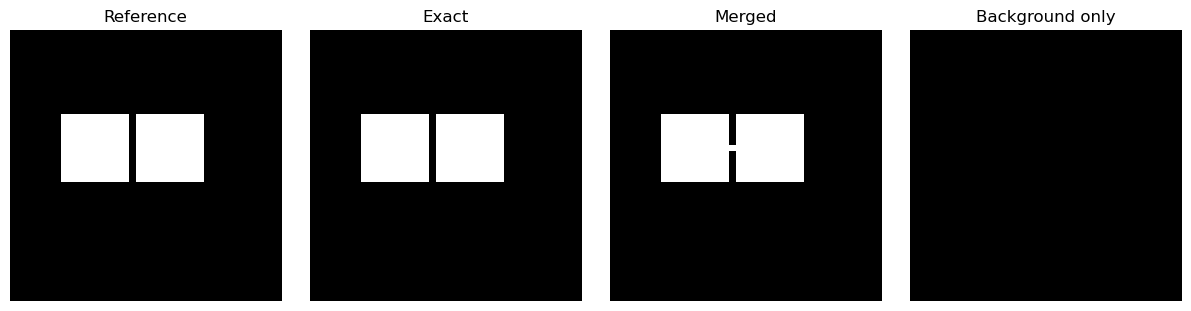

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for axis, (title, mask) in zip(axes, {"Reference": reference, **predictions}.items()):
    axis.imshow(mask, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")
plt.show()

%%markdown
## Pixel-level scores

A true positive (TP) is a building pixel in both masks; false positives (FP)
are predicted building pixels outside the reference; false negatives (FN)
are missed reference building pixels. True negatives (TN) are correctly
predicted background pixels. Accuracy includes background. Building precision
is TP/(TP+FP), recall is TP/(TP+FN), and intersection over union (IoU) is
TP/(TP+FP+FN). When nothing is predicted, precision is mathematically undefined;
this example reports it as 0 by convention, while recall is defined as 0.

In [3]:
print(f"{'Prediction':<18} {'TN':>5} {'FP':>5} {'FN':>5} {'TP':>5} {'Accuracy':>9} {'Precision':>10} {'Recall':>7} {'IoU':>7}")
for name, prediction in predictions.items():
    tn, fp, fn, tp = confusion_matrix(reference.ravel(), prediction.ravel(), labels=[False, True]).ravel()
    accuracy = (tp + tn) / reference.size
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    iou = tp / (tp + fp + fn) if tp + fp + fn else 0.0
    print(f"{name:<18} {tn:5d} {fp:5d} {fn:5d} {tp:5d} {accuracy:9.3f} {precision:10.3f} {recall:7.3f} {iou:7.3f}")

Prediction            TN    FP    FN    TP  Accuracy  Precision  Recall     IoU
Exact               5600     0     0   800     1.000      1.000   1.000   1.000
Merged              5596     4     0   800     0.999      0.995   1.000   0.995
Background only     5600     0   800     0     0.875      0.000   0.000   0.000


%%markdown
## Count with one-to-one object matching

Use 4-connected components as a proxy for individual buildings: pixels
sharing an edge are in the same object;
diagonal contact alone does not join them. A predicted component and a
reference component are eligible to match when their IoU is at least 0.40.
We choose a one-to-one assignment maximizing the number of eligible matches,
with total IoU breaking ties. A matched pair counts as one object TP; every
unmatched prediction is an object FP and every unmatched reference is an
object FN. A real evaluation needs an agreed threshold and object definition.

In [4]:
reference_objects, reference_count = ndimage.label(reference)
threshold = 0.40
print(f"Reference objects: {reference_count}; match IoU >= {threshold:.2f}")
for name, prediction in predictions.items():
    predicted_objects, predicted_count = ndimage.label(prediction)
    overlaps = np.zeros((reference_count, predicted_count))
    for ref_id in range(1, reference_count + 1):
        ref_object = reference_objects == ref_id
        for pred_id in range(1, predicted_count + 1):
            pred_object = predicted_objects == pred_id
            intersection = np.count_nonzero(ref_object & pred_object)
            union = np.count_nonzero(ref_object | pred_object)
            overlaps[ref_id - 1, pred_id - 1] = intersection / union
    eligible = overlaps >= threshold
    rows, columns = linear_sum_assignment(-(eligible + eligible * overlaps / (reference_count + 1)))
    matches = int(eligible[rows, columns].sum())
    print(f"{name:<18} predicted={predicted_count}  TP={matches}  FP={predicted_count - matches}  FN={reference_count - matches}")
    if name == "Merged":
        print("  Pairwise IoU (reference rows, prediction columns):", overlaps.round(3).tolist())

Reference objects: 2; match IoU >= 0.40
Exact              predicted=2  TP=2  FP=0  FN=0
Merged             predicted=1  TP=1  FP=0  FN=1
  Pairwise IoU (reference rows, prediction columns): [[0.498], [0.498]]
Background only    predicted=0  TP=0  FP=0  FN=2


%%markdown
The merged region overlaps both reference objects, but can match at most one.
At the 0.40 threshold it matches one building; at 0.50 it matches neither,
although the prediction still contains one object. Its high pixel IoU does
not mean that both buildings were counted. The
background-only map can have high accuracy while finding no buildings. In a
real study, evaluate on independently labeled, spatially held-out scenes;
a mapped footprint dataset is not automatically complete ground truth.

**Try it:** Raise the object IoU threshold to 0.50. Which merged object
matches remain? Then remove the bridge and compare the results again.